В этом notebook мы будем работать над улучшением метрик бейслайн моделей, путем дополнительных преобразований с данными. Существует 2 подхода:

1. Тестировать каждое преобразование отдельно и сравнивать с бейслайном, затем выбрать только лучшие и скомбинировать их
2. Поочередно применять удачные преобразования, сравнивая результат каждого нового преобразования с результатом предыдущего (итеративный подход)

Здесь мы будем использовать первый подход

## 1. Предобработка
Выполняем все те же операции, что и в бейслайне

In [1]:
# Необходимо для корректной работы внешних .py файлов
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, MinMaxScaler, TargetEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from lightgbm import LGBMClassifier
from helper import *
from plots import *
import random

In [3]:
# фиксируем состояние генератора псевдослучайных чисел. Это необходимо, чтобы результаты модели не менялись с каждым новым запуском 
SEED = 42 # можно указать любое число
np.random.seed(SEED)
random.seed(SEED)

In [4]:
df = pd.read_csv("adult.csv")

## 1.1 Общие преобразования

In [5]:
df_preprocessed = df.copy()
df_preprocessed['workclass'] = df_preprocessed['workclass'].replace('?', np.nan)
df_preprocessed['occupation'] = df_preprocessed['occupation'].replace('?', np.nan)
df_preprocessed['native-country'] = df_preprocessed['native-country'].replace('?', np.nan)
df_preprocessed = df_preprocessed.drop(columns=['educational-num'])
df_preprocessed['income'] = np.where(df_preprocessed['income'] == '>50K', 1, 0)

X, y = divide_data(df_preprocessed, 'income')


categorical_cols = ['workclass', 'education', 'marital-status', 'occupation', 'relationship','race', 'gender', 'native-country']
numeric_cols = ['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week']
most_frequent_cat_cols = ['workclass', 'occupation', 'native-country']

category_orders = [
    # workclass
    ['Federal-gov', 'Local-gov', 'Never-worked', 'Private', 
     'Self-emp-inc', 'Self-emp-not-inc', 'State-gov', 'Without-pay'],
    
    # education
    ['10th', '11th', '12th', '1st-4th', '5th-6th', '7th-8th', '9th', 
     'Assoc-acdm', 'Assoc-voc', 'Bachelors', 'Doctorate', 'HS-grad', 
     'Masters', 'Preschool', 'Prof-school', 'Some-college'],
     
    # marital-status
    ['Divorced', 'Married-AF-spouse', 'Married-civ-spouse', 
     'Married-spouse-absent', 'Never-married', 'Separated', 'Widowed'],
     
    # occupation
    ['Adm-clerical', 'Armed-Forces', 'Craft-repair', 
     'Exec-managerial', 'Farming-fishing', 'Handlers-cleaners', 
     'Machine-op-inspct', 'Other-service', 'Priv-house-serv', 
     'Prof-specialty', 'Protective-serv', 'Sales', 'Tech-support', 
     'Transport-moving'],
     
    # relationship
    ['Husband', 'Not-in-family', 'Other-relative', 'Own-child', 
     'Unmarried', 'Wife'],
     
    # race
    ['Amer-Indian-Eskimo', 'Asian-Pac-Islander', 'Black', 'Other', 'White'],
    
    # sex
    ['Male', 'Female'],
    
    # native-country
    ['Cambodia', 'Canada', 'China', 'Columbia', 'Cuba', 
     'Dominican-Republic', 'Ecuador', 'El-Salvador', 'England', 
     'France', 'Germany', 'Greece', 'Guatemala', 'Haiti', 
     'Holand-Netherlands', 'Honduras', 'Hong', 'Hungary', 'India', 
     'Iran', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Laos', 
     'Mexico', 'Nicaragua', 'Outlying-US(Guam-USVI-etc)', 'Peru', 
     'Philippines', 'Poland', 'Portugal', 'Puerto-Rico', 'Scotland', 
     'South', 'Taiwan', 'Thailand', 'Trinadad&Tobago', 'United-States', 
     'Vietnam', 'Yugoslavia']
]


preprocessor = Pipeline([
    ('nan_remover', ColumnTransformer(
        [
            ('most_frequent_cat', SimpleImputer(strategy='most_frequent'), most_frequent_cat_cols),
        ],
        remainder='passthrough',  
        verbose_feature_names_out=False  
    )),
    
    ('transformations', ColumnTransformer(
        [('encoder', OrdinalEncoder(categories=category_orders), categorical_cols)],
        remainder='passthrough',  
        verbose_feature_names_out=False
    ))
])

preprocessor.set_output(transform="pandas")


,steps,"[('nan_remover', ...), ('transformations', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('most_frequent_cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [6]:
# сохраним все бейслайн модели в виде списка для удобства
models = [
    ('LogisticRegression', LogisticRegression(random_state=SEED, max_iter=1000, solver='liblinear')),
    ('DecisionTreeClassifier', DecisionTreeClassifier(random_state=SEED, max_depth=4)),
    ('RandomForestClassifier', RandomForestClassifier(random_state=SEED)),
    ('LGBMClassifier', LGBMClassifier(random_state=SEED))
]

In [7]:
# используем 5-блочную кросс-валидацию, учитывающую распределение таргета при разбиении
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006589 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 700
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002913 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 702
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[Light

<Figure size 1500x600 with 0 Axes>

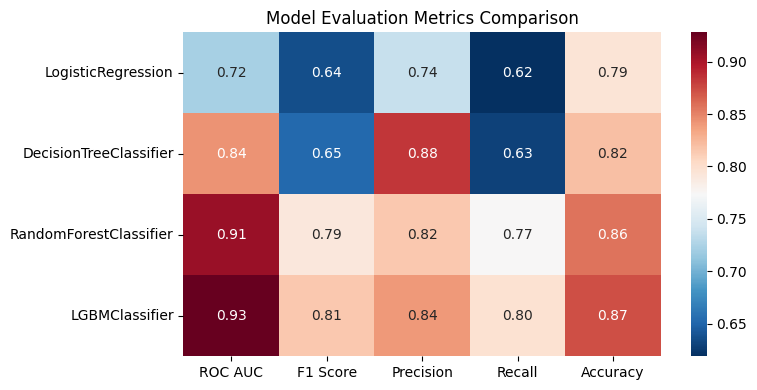

In [8]:
initial_metrics = train_evaluate_models_cv(
    models=models,
    X=X,
    y=y,
    preprocessor=preprocessor,
    cv=cv,
    seed=SEED
)

## 2. Преобразования данных и feature engineering

### 2.1 Логарифмическое преобразование
В нашем датасете имеются "денежные" признаки capital-gain, capital-loss, fnlwgt, которые имеют асимметричное распределение. Логарифмирование позволит сделать их более нормальными

In [9]:
# Количество нулевых значений в каждом столбце
print("capital-gain:", (df['capital-gain'] == 0).sum())
print("capital-loss:", (df['capital-loss'] == 0).sum())
print("fnlwgt:", (df['fnlwgt'] == 0).sum())

capital-gain: 44807
capital-loss: 46560
fnlwgt: 0


In [18]:
# Процент нулей от общего количества записей
total = len(df)
print(f"capital-gain: {(df['capital-gain'] == 0).sum()} ({(df['capital-gain'] == 0).sum()/total*100:.2f}%)")
print(f"capital-loss: {(df['capital-loss'] == 0).sum()} ({(df['capital-loss'] == 0).sum()/total*100:.2f}%)")
print(f"fnlwgt: {(df['fnlwgt'] == 0).sum()} ({(df['fnlwgt'] == 0).sum()/total*100:.2f}%)")

capital-gain: 44807 (91.74%)
capital-loss: 46560 (95.33%)
fnlwgt: 0 (0.00%)


В capital-gain и capital-loss много нулевых значений. Так понимаю, что логарифмирование в этом случае бесполезно

#### 2.1.1 Без удаления столбцов

In [35]:
X_log = X.copy()

In [36]:
X_log['fnlwgt'] = np.log1p(X_log['fnlwgt'])

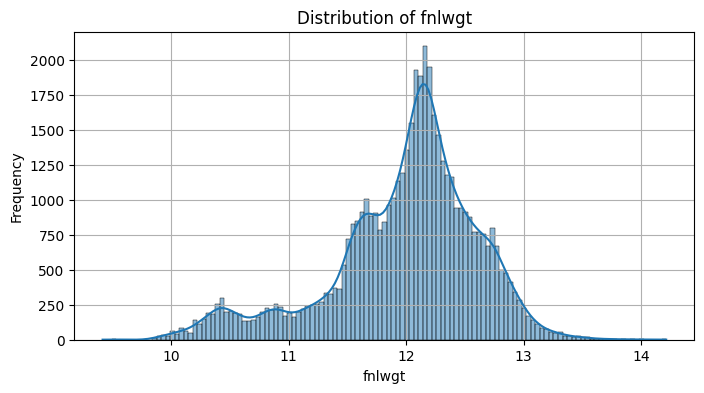

In [37]:
plot_hist_numeric(X_log, 'fnlwgt')

В результате логарифмирования распределение fnlwgt стало ближе к нормальному

In [38]:
preprocessor_log = clone(preprocessor)

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004097 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 700
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002790 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 702
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [bin

<Figure size 1500x600 with 0 Axes>

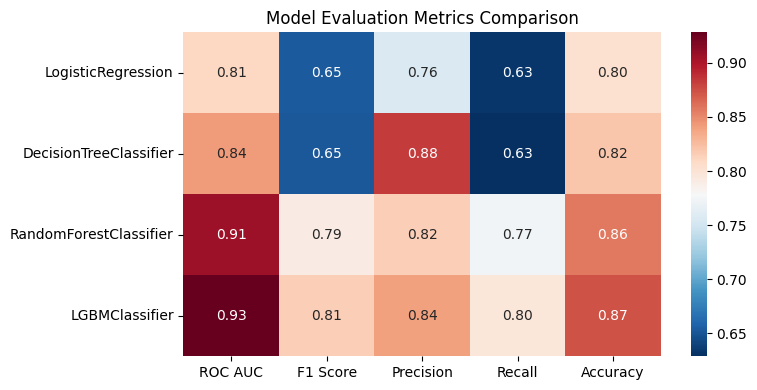

In [39]:
log_metrics = train_evaluate_models_cv(
    models=models,
    X=X_log,
    y=y,
    preprocessor=preprocessor_log,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                              ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression      8.319133e-02  0.007552  -0.008785  0.006566 -0.000676
 DecisionTreeClassifier  0.000000e+00  0.000000   0.000000  0.000000  0.000000
 RandomForestClassifier -6.796010e-05 -0.000400  -0.000341 -0.000425 -0.000246
 LGBMClassifier         -8.633750e-07  0.000000   0.000000  0.000000  0.000000)

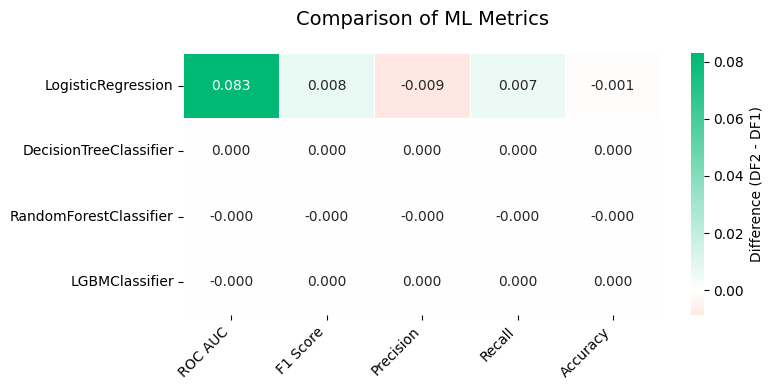

In [21]:
# сравним изначальные метрики с метриками после логарифмирования и выведем график
compare_metrics_heatmap(initial_metrics, log_metrics)

Наблюдаем незначительные колебания метрик, улучшения практически нет

#### 2.1.2 С удалением исходных столбцов

In [22]:
X_log_delete = X.copy()

In [23]:
X_log_delete['fnlwgt'] = np.log1p(X_log_delete['fnlwgt'])

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002934 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 700
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002822 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 702
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [bin

<Figure size 1500x600 with 0 Axes>

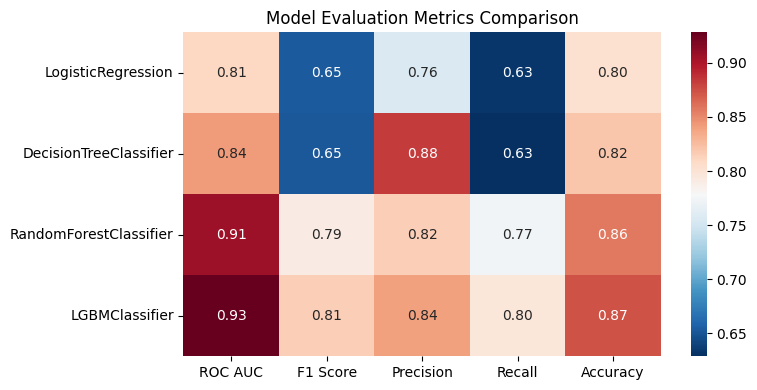

In [24]:
log_delete_metrics = train_evaluate_models_cv(
    models=models,
    X=X_log_delete,
    y=y,
    preprocessor=preprocessor,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                              ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression      8.698799e-02  0.017365   0.017397  0.013756  0.007944
 DecisionTreeClassifier  0.000000e+00  0.000000   0.000000  0.000000  0.000000
 RandomForestClassifier -1.013148e-05 -0.000437  -0.000365 -0.000468 -0.000266
 LGBMClassifier         -8.633750e-07  0.000000   0.000000  0.000000  0.000000)

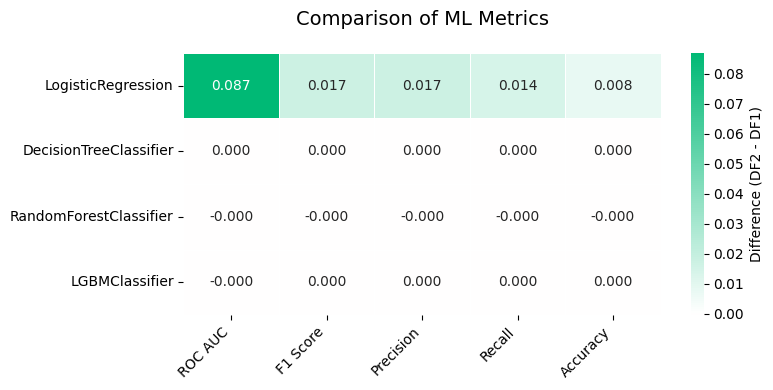

In [25]:
compare_metrics_heatmap(initial_metrics, log_delete_metrics)

C удалением столбца ничего не изменилось 

### 2.2 Создание нового признака "net_capital"
Возможно, люди с высоким приростом капитала чаще имеют доход >50K

capital-gain - capital-loss

In [26]:
X_net_capital = X.copy()

In [27]:
X_net_capital['net_capital'] = X_net_capital['capital-gain'] - X_net_capital['capital-loss']
X_net_capital = X_net_capital.drop(columns=['capital-gain', 'capital-gain'])

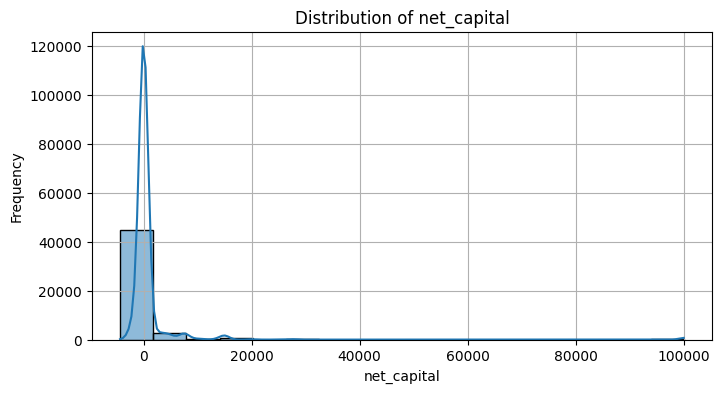

In [28]:
plot_hist_numeric(X_net_capital, 'net_capital')

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003135 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 771
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005097 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 776
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [bin

<Figure size 1500x600 with 0 Axes>

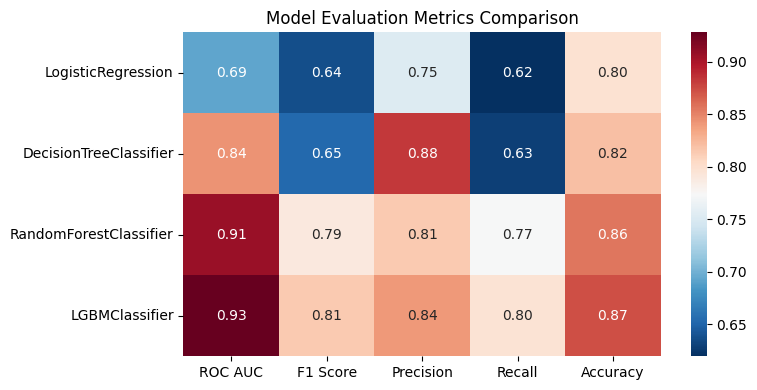

In [29]:
total_income_metrics = train_evaluate_models_cv(
    models=models,
    X=X_net_capital,
    y=y,
    preprocessor=preprocessor,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                          ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression     -0.030086  0.001481   0.014748  0.000743  0.003583
 DecisionTreeClassifier  0.000044  0.000153  -0.000086  0.000115  0.000041
 RandomForestClassifier  0.000357 -0.000780  -0.001066 -0.000625 -0.000594
 LGBMClassifier          0.000110 -0.000194   0.000169 -0.000379 -0.000041)

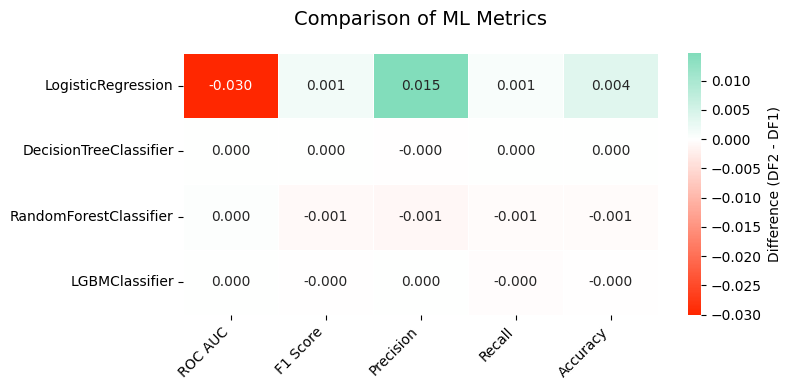

In [30]:
compare_metrics_heatmap(initial_metrics, total_income_metrics)

Улучшения не произошло

### 2.3 Отношение кредита к доходу (Loan-to-Income Ratio, LIR)

In [31]:
X_capital_ratio = X.copy()

In [32]:
X_capital_ratio['capital_ratio'] = X_capital_ratio['capital-gain'] / (X_capital_ratio['hours-per-week'] * 52 + 1)  # +1 чтобы избежать деления на 0

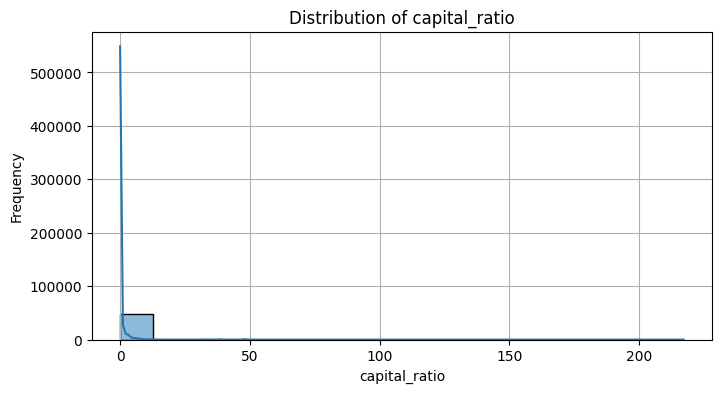

In [34]:
plot_hist_numeric(X_capital_ratio, 'capital_ratio')

In [35]:
preprocessor_capital_ratio = clone(preprocessor)

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003091 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 953
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003125 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 956
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 14
[LightGBM] [Info] [bin

<Figure size 1500x600 with 0 Axes>

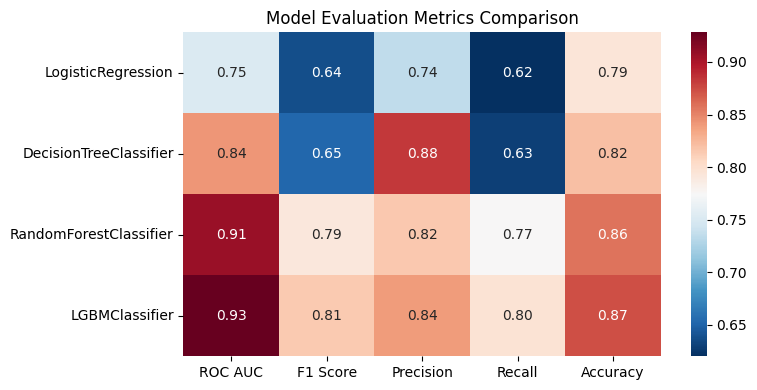

In [37]:
capital_ratio_metrics = train_evaluate_models_cv(
    models=models,
    X=X_capital_ratio,
    y=y,
    preprocessor=preprocessor_capital_ratio,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                          ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression      0.029712  0.001871  -0.002354  0.001498 -0.000041
 DecisionTreeClassifier  0.000060  0.000037  -0.000123  0.000029  0.000000
 RandomForestClassifier  0.000017  0.000090  -0.000169  0.000221 -0.000021
 LGBMClassifier          0.000021 -0.000270   0.000023 -0.000419 -0.000102)

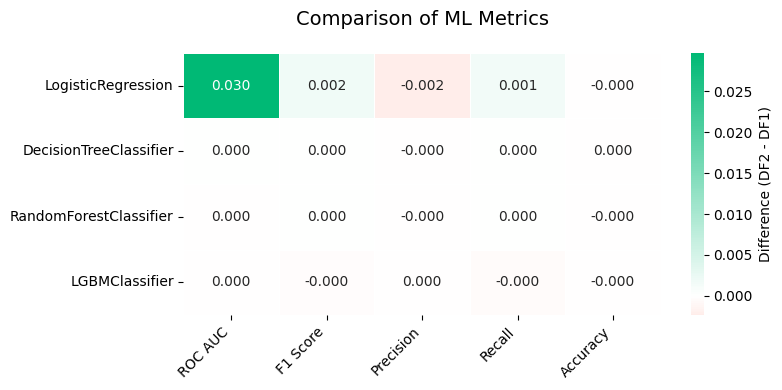

In [38]:
compare_metrics_heatmap(initial_metrics, capital_ratio_metrics)

Особо ничего не изменилось

### 2.4 Биннинг для hours-per-week
Попробуем сделать биннинг для hours-per-week

#### 2.4.1 Без удаления

In [49]:
X_hours_binning = X.copy()

In [50]:
bins = [-np.inf, 30, 40, 50, np.inf]
labels = [0, 1, 2, 3]

X_hours_binning['hours_per_week_bins'] = pd.cut(
    X_hours_binning['hours-per-week'], 
    bins=bins, 
    labels=labels
)

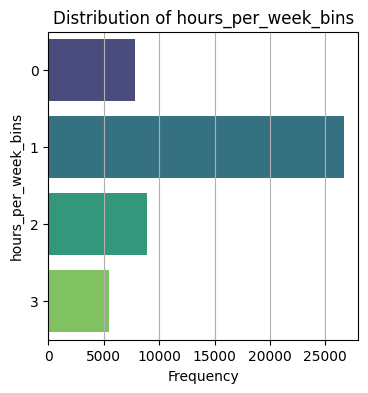

In [51]:
plot_hist_categorical(X_hours_binning, 'hours_per_week_bins')

In [52]:
preprocessor_hours_binning = clone(preprocessor)


<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002837 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 704
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002959 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 706
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 14
[LightGBM] [Info] [bin

<Figure size 1500x600 with 0 Axes>

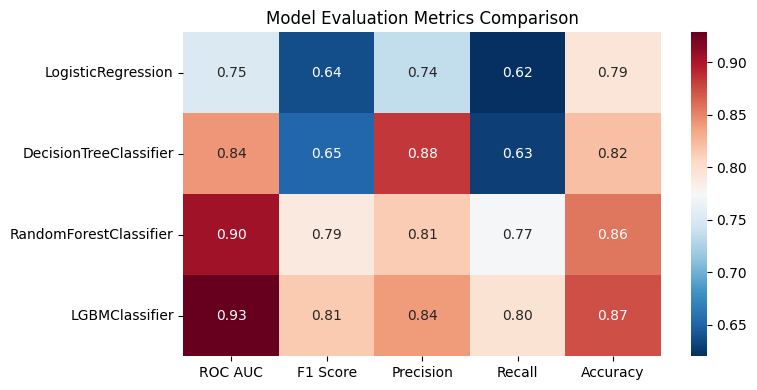

In [53]:
hours_binning_metrics = train_evaluate_models_cv(
    models=models,
    X=X_hours_binning,
    y=y,
    preprocessor=preprocessor_hours_binning,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                          ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression      0.029749  0.001837  -0.001991  0.001464  0.000041
 DecisionTreeClassifier  0.000060  0.000037  -0.000123  0.000029  0.000000
 RandomForestClassifier -0.002282 -0.001954  -0.002583 -0.001585 -0.001474
 LGBMClassifier          0.000073  0.000228   0.000033  0.000331  0.000102)

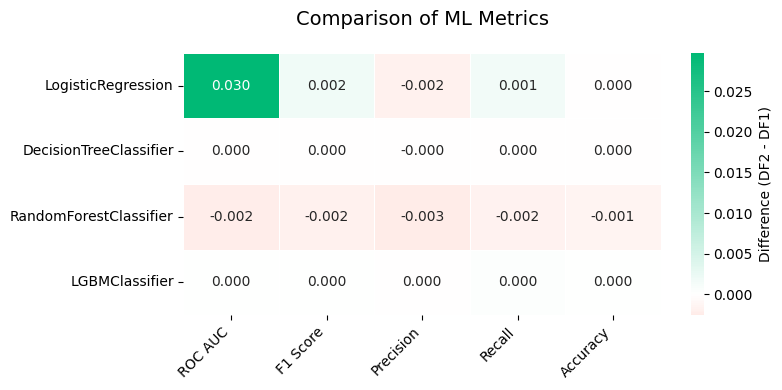

In [54]:
compare_metrics_heatmap(initial_metrics, hours_binning_metrics)

Улучшения практически не наблюдается

#### 2.4.2 С удалением

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003164 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 615
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003146 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 617
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [bin

<Figure size 1500x600 with 0 Axes>

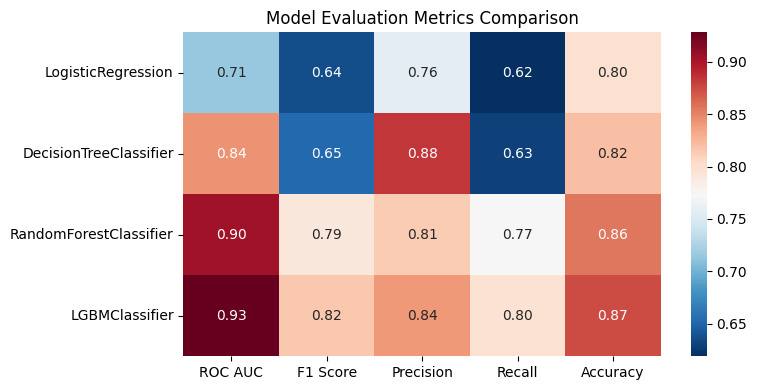

In [55]:
X_hours_binning_del = X.copy()
bins = [-np.inf, 30, 40, 50, np.inf]
labels = [0, 1, 2, 3]

X_hours_binning_del['hours-per-week'] = pd.cut(
    X_hours_binning_del['hours-per-week'], 
    bins=bins, 
    labels=labels
)

hours_binning_metrics_del = train_evaluate_models_cv(
    models=models,
    X=X_hours_binning_del,
    y=y,
    preprocessor=preprocessor,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                          ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression     -0.007679  0.000991   0.019603  0.000177  0.004729
 DecisionTreeClassifier  0.000142  0.000000   0.000000  0.000000  0.000000
 RandomForestClassifier -0.002266 -0.000739  -0.002206  0.000042 -0.000962
 LGBMClassifier          0.000062  0.000564   0.000934  0.000369  0.000471)

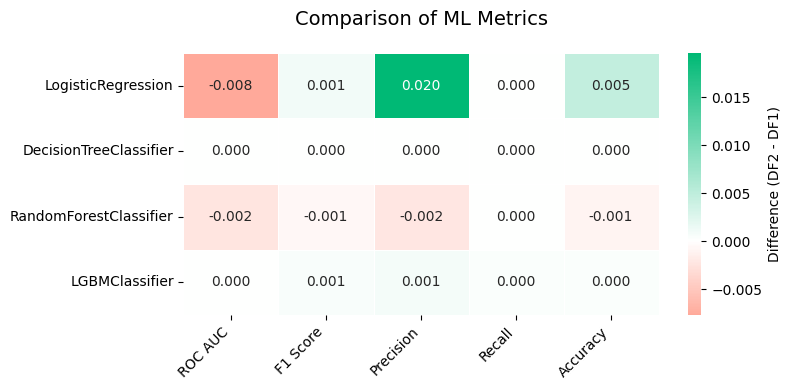

In [56]:
compare_metrics_heatmap(initial_metrics, hours_binning_metrics_del)

(<Figure size 800x400 with 2 Axes>,
                          ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression     -0.037428 -0.000847   0.021594 -0.001287  0.004688
 DecisionTreeClassifier  0.000082 -0.000037   0.000123 -0.000029  0.000000
 RandomForestClassifier  0.000016  0.001215   0.000377  0.001627  0.000512
 LGBMClassifier         -0.000012  0.000336   0.000901  0.000037  0.000369)

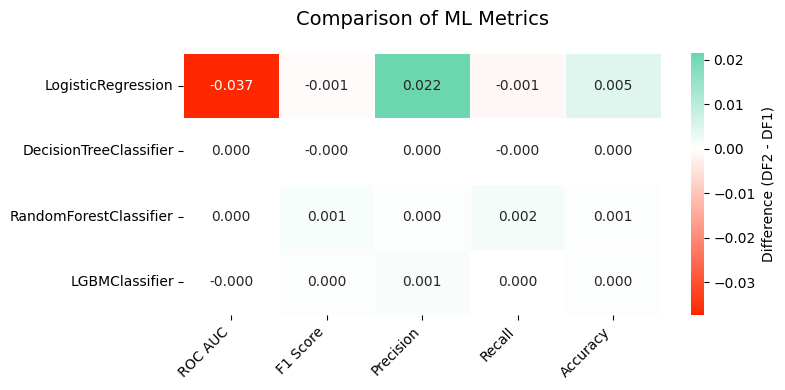

In [57]:
compare_metrics_heatmap(hours_binning_metrics, hours_binning_metrics_del)

Улучшения нет

### 2.5 Применение StandardScaler (стандартизация)

#### 2.5.1 Без удаления

In [24]:
X_standard_scaler = X.copy()

In [25]:

scaled_columns = ['ageScaled', 'fnlwgtScaled', 'capital-gainScaled', 'capital-lossScaled', 'hours-per-weekScaled']
X_standard_scaler[scaled_columns] = X_standard_scaler[['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week']]

In [26]:
preprocessor_standard_scaler = clone(preprocessor)

preprocessor_standard_scaler['transformations'].transformers.append(
    ('scaler', StandardScaler(), scaled_columns)
)
preprocessor_standard_scaler['nan_remover'].transformers[0][2].extend(scaled_columns)


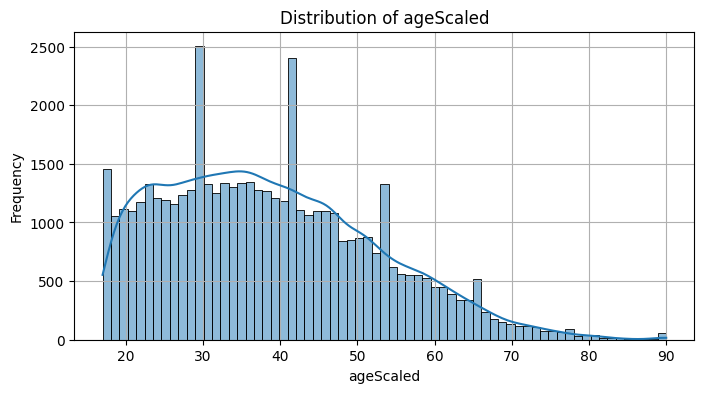

In [27]:
plot_hist_numeric(X_standard_scaler, 'ageScaled')

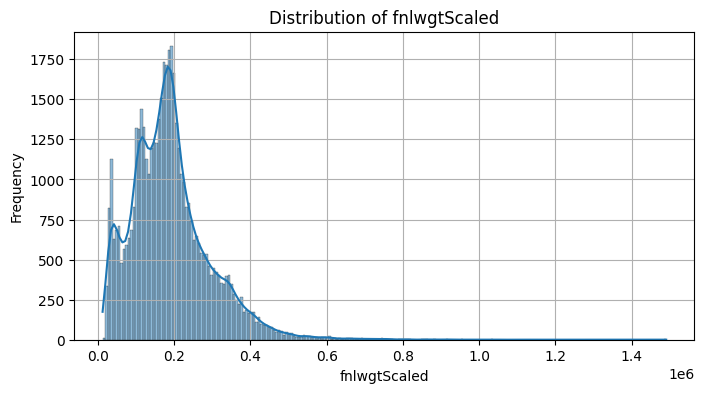

In [28]:
plot_hist_numeric(X_standard_scaler, 'fnlwgtScaled')

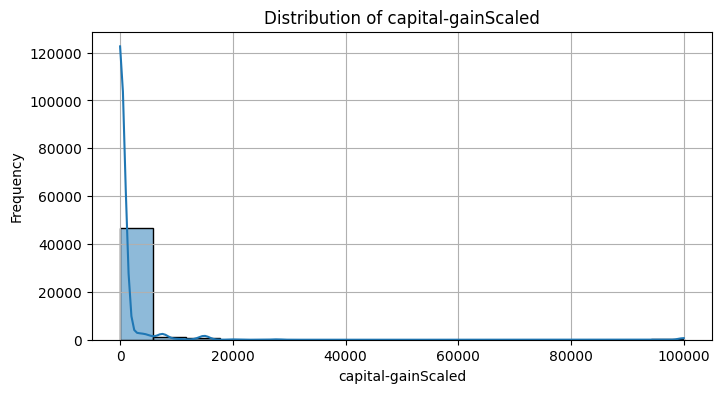

In [29]:
plot_hist_numeric(X_standard_scaler, 'capital-gainScaled')

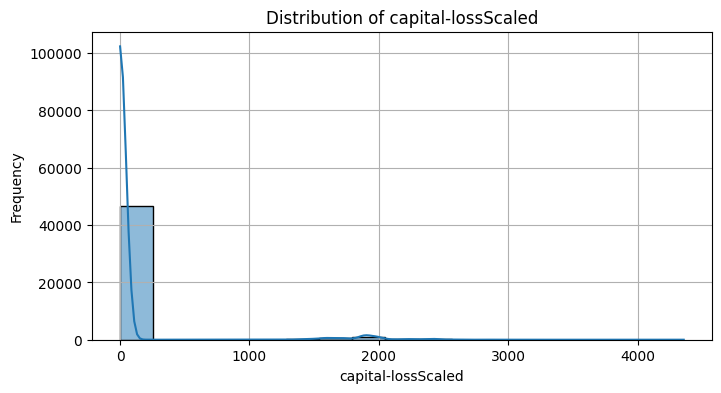

In [30]:
plot_hist_numeric(X_standard_scaler, 'capital-lossScaled')

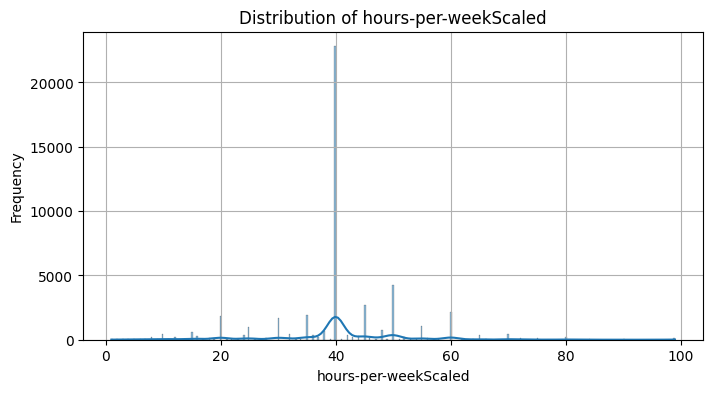

In [31]:
plot_hist_numeric(X_standard_scaler, 'hours-per-weekScaled')

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003417 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1304
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003308 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1308
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 18
[LightGBM] [Info] [b

<Figure size 1500x600 with 0 Axes>

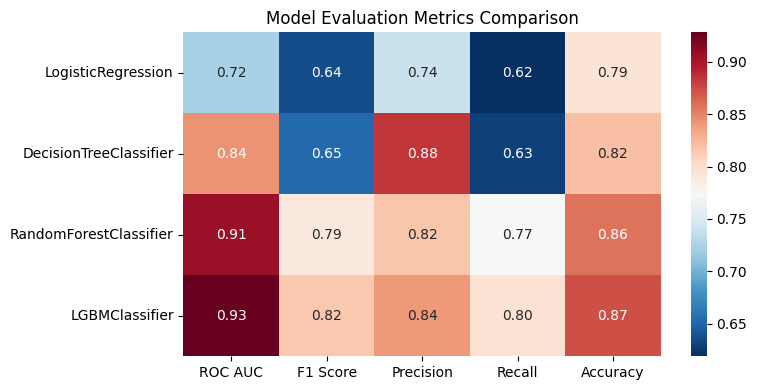

In [32]:
standard_scaler_metrics = train_evaluate_models_cv(
    models=models,
    X=X_standard_scaler,
    y=y,
    preprocessor=preprocessor_standard_scaler,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                          ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression      0.001173  0.000136   0.000763  0.000089  0.000225
 DecisionTreeClassifier -0.000086 -0.000058  -0.000016 -0.000043 -0.000020
 RandomForestClassifier  0.000061 -0.000801   0.001004 -0.001704  0.000041
 LGBMClassifier          0.000112  0.000428   0.000684  0.000287  0.000348)

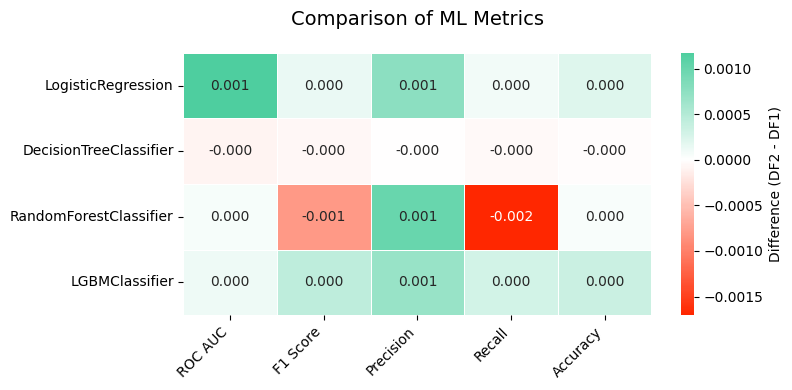

In [33]:
compare_metrics_heatmap(initial_metrics, standard_scaler_metrics)

Улучшения снова не значительные

(<Figure size 800x400 with 2 Axes>,
                          ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression     -0.085815 -0.017229  -0.016634 -0.013666 -0.007719
 DecisionTreeClassifier -0.000086 -0.000058  -0.000016 -0.000043 -0.000020
 RandomForestClassifier  0.000071 -0.000364   0.001370 -0.001235  0.000307
 LGBMClassifier          0.000113  0.000428   0.000684  0.000287  0.000348)

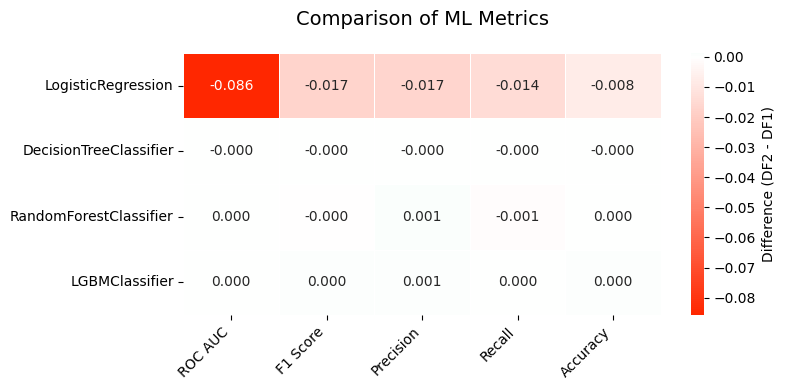

In [40]:
compare_metrics_heatmap(log_metrics, standard_scaler_metrics)

#### 2.5.2 С удалением

In [71]:
X_standard_scaler_del = X.copy()

In [72]:
preprocessor_standard_scaler_del = clone(preprocessor)

preprocessor_standard_scaler_del['transformations'].transformers.append(
    ('scaler', StandardScaler(), ['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week'])
)

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002860 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 702
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003402 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 704
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [bin

<Figure size 1500x600 with 0 Axes>

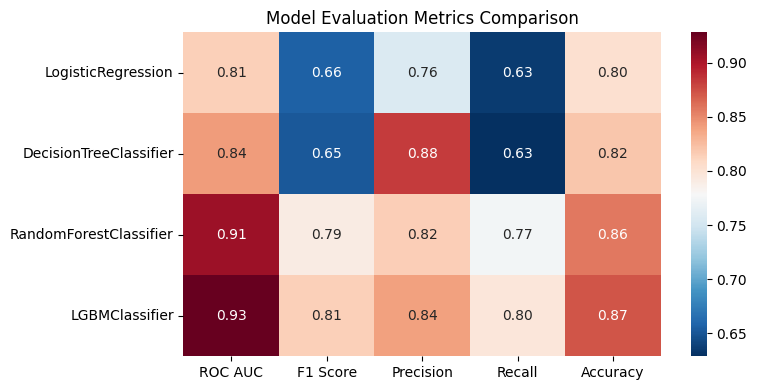

In [73]:
standard_scaler_metrics_del = train_evaluate_models_cv(
    models=models,
    X=X_standard_scaler_del,
    y=y,
    preprocessor=preprocessor_standard_scaler_del,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                          ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression      0.091799  0.020058   0.018504  0.016022  0.008804
 DecisionTreeClassifier  0.000000  0.000000   0.000000  0.000000  0.000000
 RandomForestClassifier -0.000011 -0.000268  -0.000427 -0.000177 -0.000225
 LGBMClassifier         -0.000019 -0.000467  -0.000537 -0.000420 -0.000328)

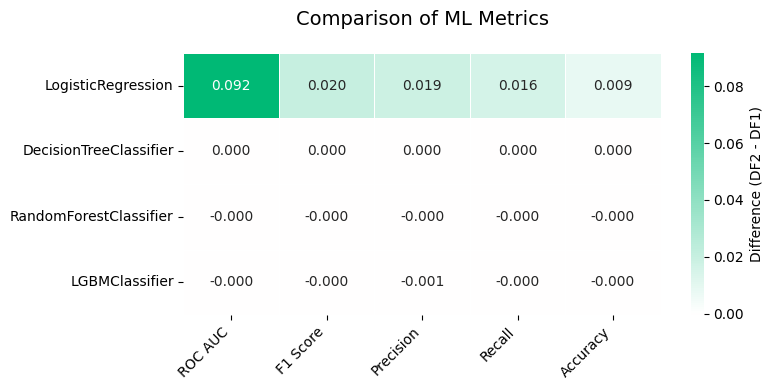

In [74]:
compare_metrics_heatmap(initial_metrics, standard_scaler_metrics_del)

Улучшилась только логистическая регрессия совсем немного

### 2.6 Нормализация

#### 2.6.1 Без удаления

In [11]:
X_normalised = X.copy()

scaled_columns = ['ageScaled', 'fnlwgtScaled', 'capital-gainScaled', 'capital-lossScaled', 'hours-per-weekScaled']
X_normalised[scaled_columns] = X_normalised[['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week']]

preprocessor_normalisation = clone(preprocessor)

preprocessor_normalisation['transformations'].transformers.append(
    ('scaler', MinMaxScaler(), scaled_columns)
)

preprocessor_normalisation['nan_remover'].transformers[0][2].extend(scaled_columns)


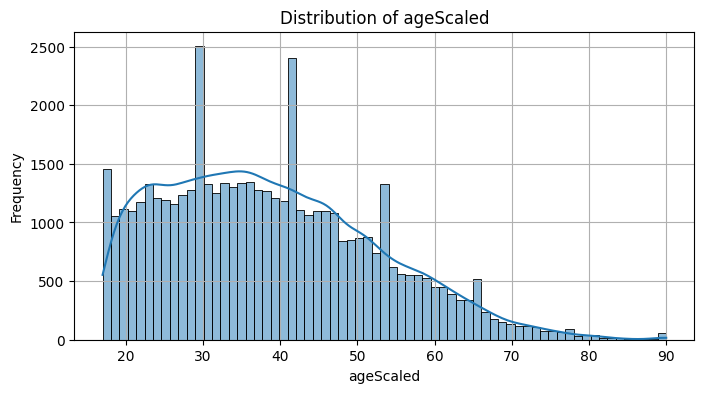

In [12]:
plot_hist_numeric(X_normalised, 'ageScaled')

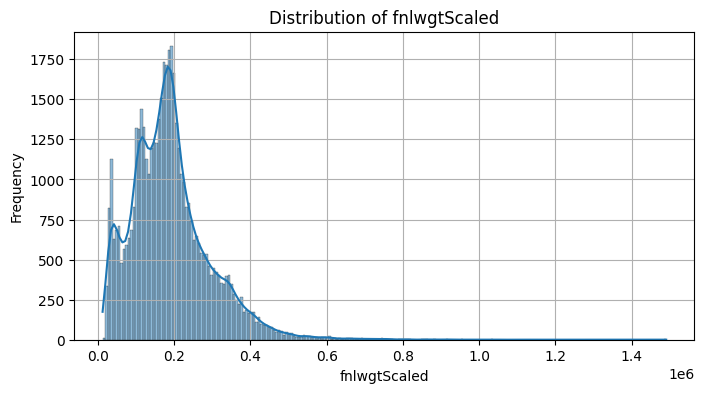

In [13]:
plot_hist_numeric(X_normalised, 'fnlwgtScaled')

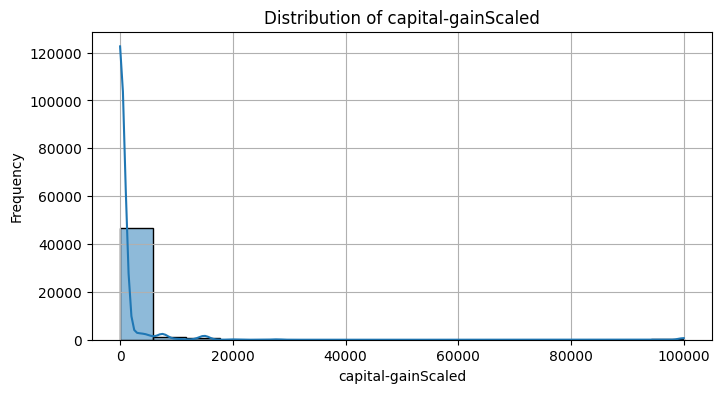

In [14]:
plot_hist_numeric(X_normalised, 'capital-gainScaled')

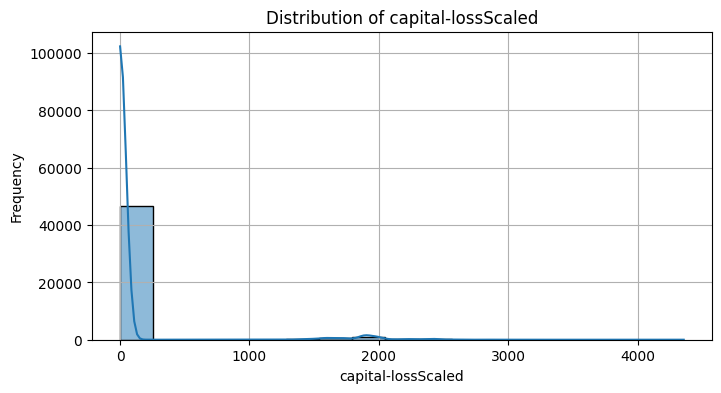

In [15]:
plot_hist_numeric(X_normalised, 'capital-lossScaled')

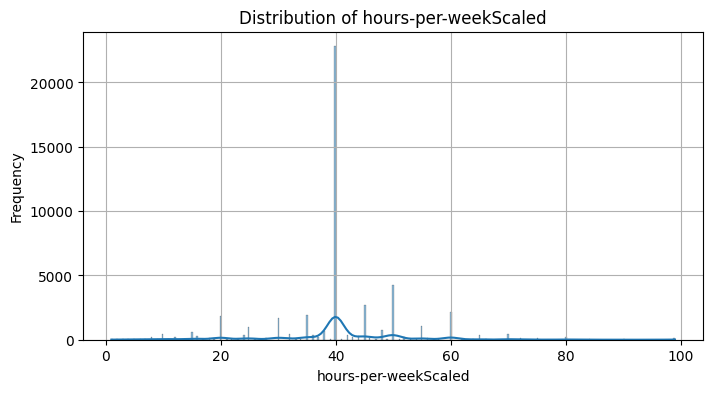

In [16]:
plot_hist_numeric(X_normalised, 'hours-per-weekScaled')

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006424 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1300
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007212 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1304
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[Lig

<Figure size 1500x600 with 0 Axes>

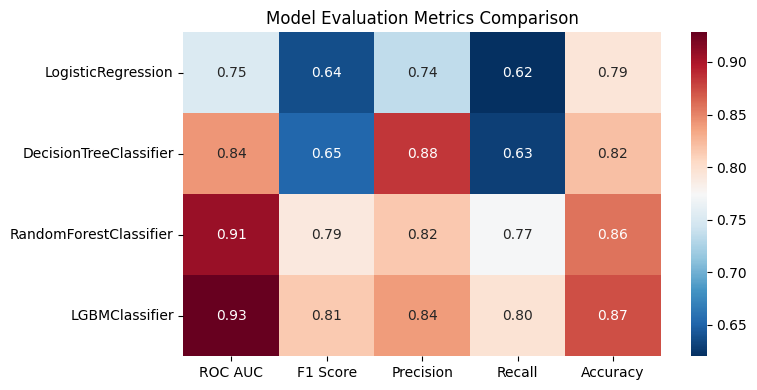

In [17]:
normalised_metrics = train_evaluate_models_cv(
    models=models,
    X=X_normalised,
    y=y,
    preprocessor=preprocessor_normalisation,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                              ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression      2.922275e-02  0.001834  -0.002478  0.001471 -0.000082
 DecisionTreeClassifier -8.553169e-05 -0.000058  -0.000016 -0.000043 -0.000020
 RandomForestClassifier  6.304825e-05 -0.001226   0.000751 -0.002204 -0.000184
 LGBMClassifier         -3.339812e-07  0.000000   0.000000  0.000000  0.000000)

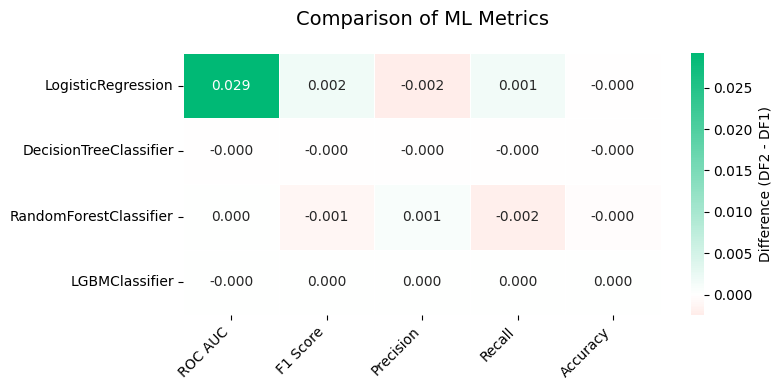

In [18]:
compare_metrics_heatmap(initial_metrics, normalised_metrics)

Совсем небольшое улучшение у логистической регрессии

#### 2.6.2 С удалением

In [20]:
X_normalised_del = X.copy()

In [21]:
preprocessor_normalisation_del = clone(preprocessor)

preprocessor_normalisation_del['transformations'].transformers.append(
    ('scaler', MinMaxScaler(), ['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week'])
)

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003487 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 698
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002836 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 700
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [bin

<Figure size 1500x600 with 0 Axes>

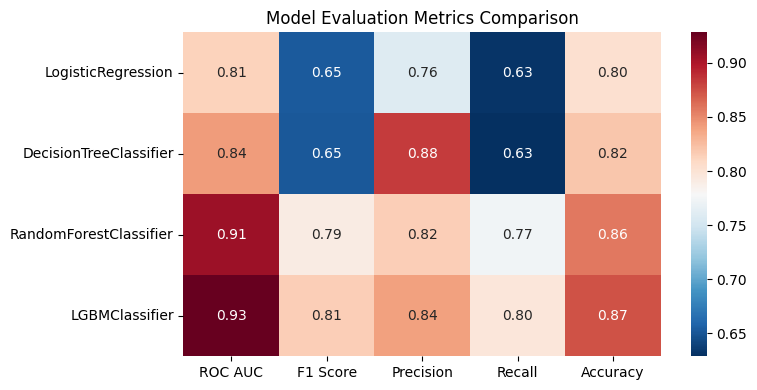

In [22]:
normalised_metrics_del = train_evaluate_models_cv(
    models=models,
    X=X_normalised_del,
    y=y,
    preprocessor=preprocessor_normalisation_del,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                          ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression      0.090981  0.016389   0.021146  0.012765  0.008579
 DecisionTreeClassifier  0.000000  0.000000   0.000000  0.000000  0.000000
 RandomForestClassifier -0.000054 -0.000284  -0.000210 -0.000313 -0.000164
 LGBMClassifier          0.000002  0.000000   0.000000  0.000000  0.000000)

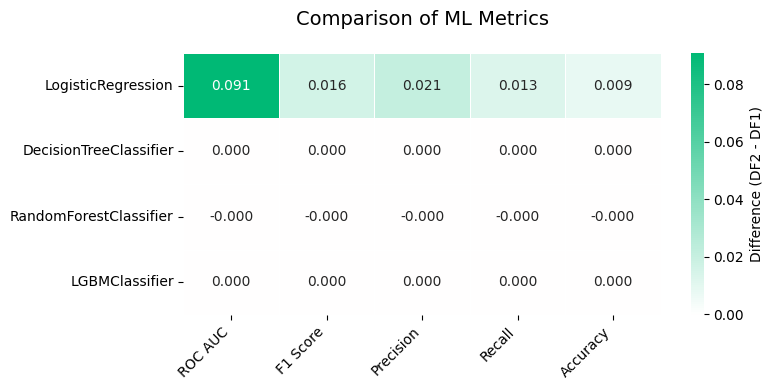

In [23]:
compare_metrics_heatmap(initial_metrics, normalised_metrics_del)

Улучшение метрик у логистической регрессии

### 2.7 Обработка выбросов

In [130]:
X_no_outliers = X.copy()

In [131]:
upper_bound_age = X_no_outliers['age'].quantile(0.95)
upper_bound_capital_gain = X_no_outliers['capital-gain'].quantile(0.95)
upper_bound_capital_loss = X_no_outliers['capital-loss'].quantile(0.95)
upper_bound_hours_per_week = X_no_outliers['hours-per-week'].quantile(0.95)


print(f"95-й процентиль age: {upper_bound_age}")
print(f"95-й процентиль capital-gain: {upper_bound_capital_gain}")
print(f"95-й процентиль capital-loss: {upper_bound_capital_loss}")
print(f"95-й процентиль hours-per-week: {upper_bound_hours_per_week}")

95-й процентиль age: 63.0
95-й процентиль capital-gain: 5013.0
95-й процентиль capital-loss: 0.0
95-й процентиль hours-per-week: 60.0


In [132]:
upper_bound_capital_loss = X_no_outliers['capital-loss'].quantile(0.96)
print(f"96-й процентиль capital-loss: {upper_bound_capital_loss}")

96-й процентиль capital-loss: 1590.0


In [133]:
X_no_outliers = winsorize_outliers(X_no_outliers, 'age', upper_bound=63)
X_no_outliers = winsorize_outliers(X_no_outliers, 'capital-gain', upper_bound=5013)
X_no_outliers = winsorize_outliers(X_no_outliers, 'capital-loss', upper_bound=1590)
X_no_outliers = winsorize_outliers(X_no_outliers, 'hours-per-week', upper_bound=60)


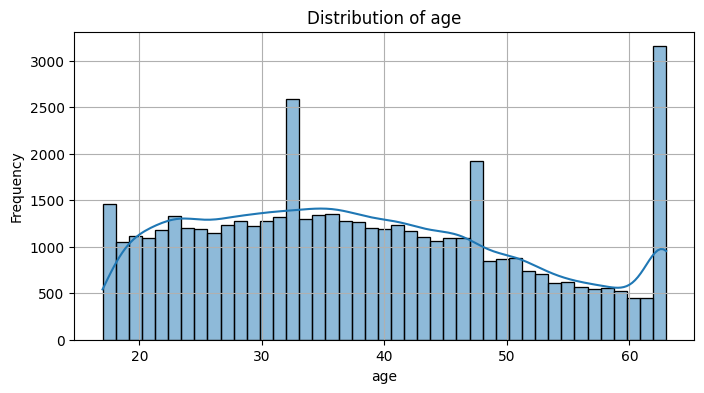

In [134]:
plot_hist_numeric(X_no_outliers, 'age')

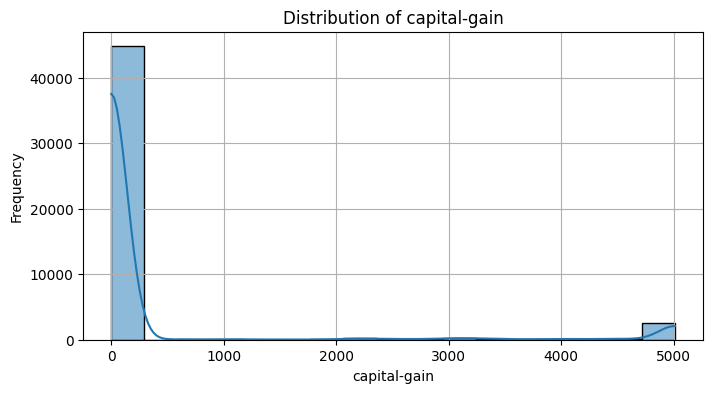

In [135]:
plot_hist_numeric(X_no_outliers, 'capital-gain')

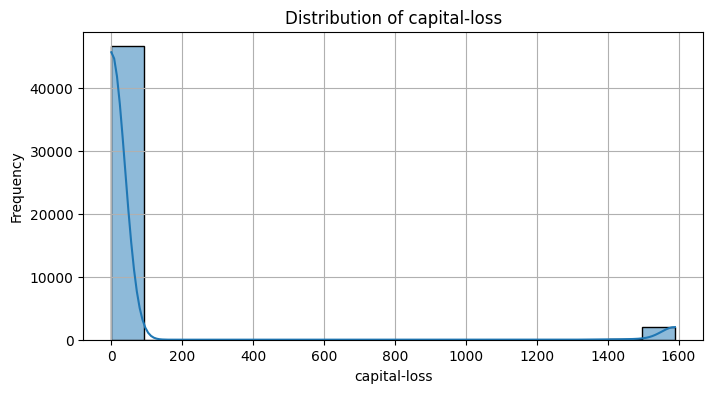

In [136]:
plot_hist_numeric(X_no_outliers, 'capital-loss')

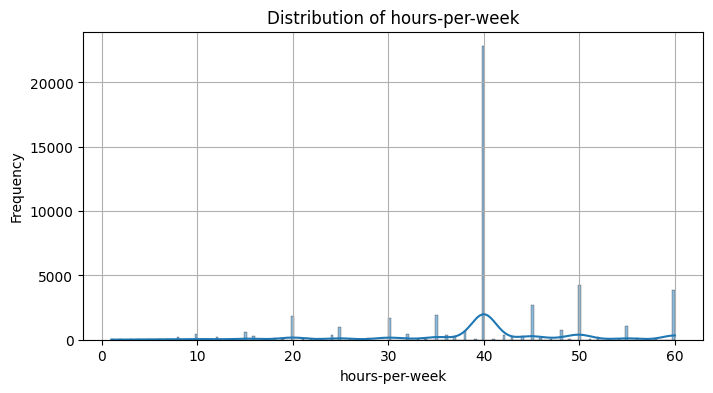

In [137]:
plot_hist_numeric(X_no_outliers, 'hours-per-week')

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002860 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 556
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002862 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 558
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [bin

<Figure size 1500x600 with 0 Axes>

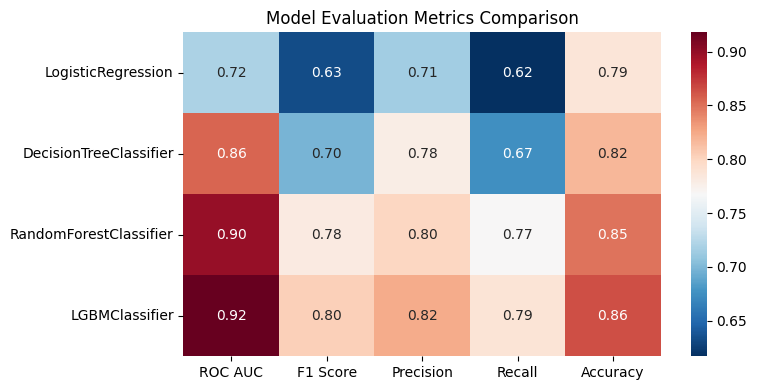

In [138]:
no_outliers_metrics = train_evaluate_models_cv(
    models=models,
    X=X_no_outliers,
    y=y,
    preprocessor=preprocessor,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                          ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression     -0.002573 -0.003024  -0.023321 -0.001827 -0.006798
 DecisionTreeClassifier  0.012770  0.045684  -0.105409  0.046050 -0.003194
 RandomForestClassifier -0.008562 -0.009852  -0.015963 -0.006327 -0.008599
 LGBMClassifier         -0.010252 -0.011969  -0.017398 -0.008721 -0.009521)

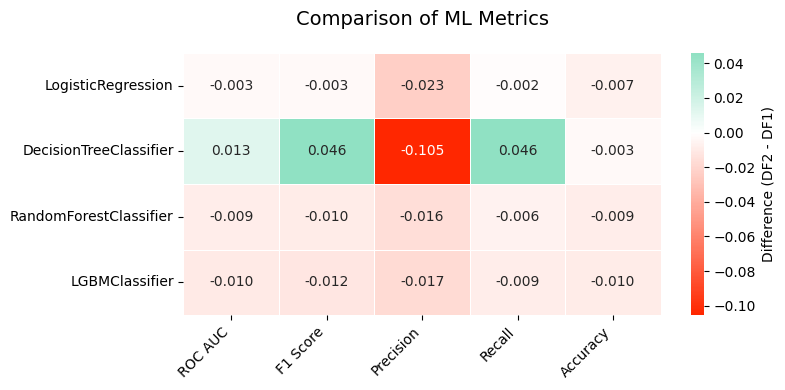

In [139]:
compare_metrics_heatmap(initial_metrics, no_outliers_metrics)

Ощутимых улучшений не наблюдается

### 2.9 Таргетное кодирование

In [140]:
preprocessor_target_encoding = clone(preprocessor)
preprocessor_target_encoding['transformations'].transformers[0] = ('encoder', TargetEncoder(categories=category_orders), categorical_cols)

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003983 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1058
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002709 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1068
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [In

<Figure size 1500x600 with 0 Axes>

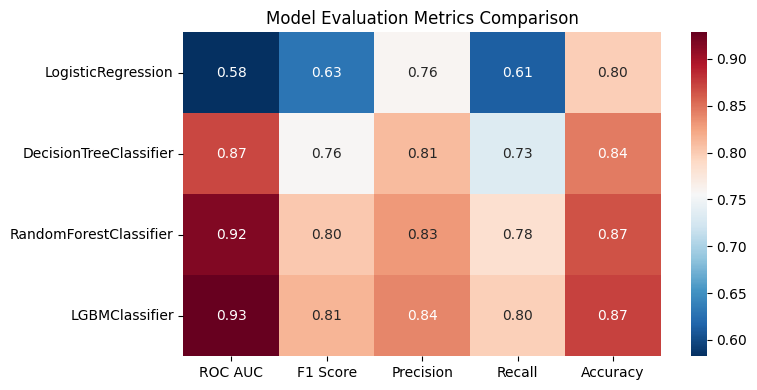

In [141]:
target_encoder_metrics = train_evaluate_models_cv(
    models=models,
    X=X,
    y=y,
    preprocessor=preprocessor_target_encoding,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                          ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression     -0.139667 -0.006393   0.021405 -0.005621  0.003583
 DecisionTreeClassifier  0.028594  0.105921  -0.073578  0.102847  0.024364
 RandomForestClassifier  0.009241  0.011122   0.014357  0.009206  0.008251
 LGBMClassifier          0.000243 -0.000095  -0.000634  0.000188 -0.000205)

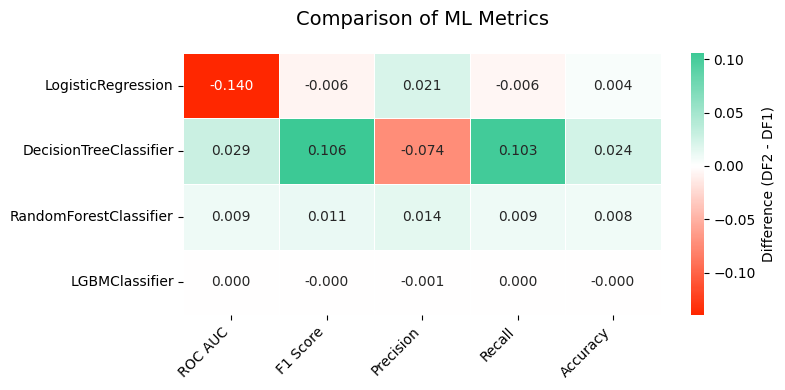

In [142]:
compare_metrics_heatmap(initial_metrics, target_encoder_metrics)

Совсем небольшое улучшение у DecisionTree

### 2.10 Работа с дисбалансом классов

#### 2.10.1 На уровне моделей

In [143]:
models_balanced = [
    ('LogisticRegression', LogisticRegression(random_state=SEED, max_iter=1000, solver='liblinear', class_weight='balanced')),
    ('DecisionTreeClassifier', DecisionTreeClassifier(random_state=SEED, max_depth=4, class_weight='balanced')),
    ('RandomForestClassifier', RandomForestClassifier(random_state=SEED, class_weight='balanced')),
    ('LGBMClassifier', LGBMClassifier(random_state=SEED, class_weight='balanced'))
]

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002449 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 700
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003671 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 702
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [bin

<Figure size 1500x600 with 0 Axes>

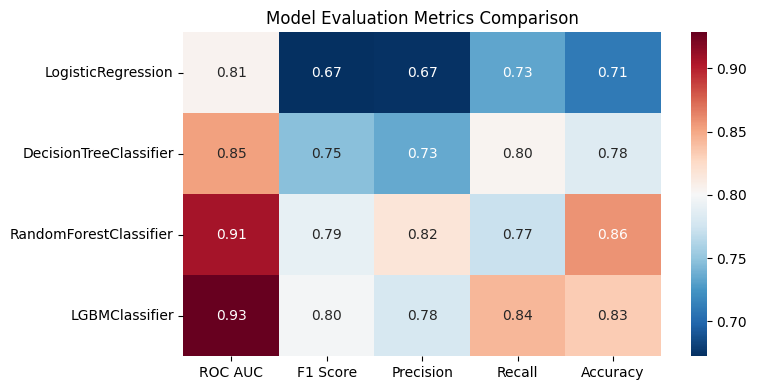

In [144]:
balanced_metrics = train_evaluate_models_cv(
    models=models_balanced,
    X=X,
    y=y,
    preprocessor=preprocessor,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                          ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression      0.083023  0.036439  -0.064347  0.113907 -0.084272
 DecisionTreeClassifier  0.009908  0.094723  -0.149057  0.175079 -0.036935
 RandomForestClassifier -0.000122 -0.001086   0.001888 -0.002564  0.000205
 LGBMClassifier          0.000297 -0.017266  -0.061769  0.046898 -0.040191)

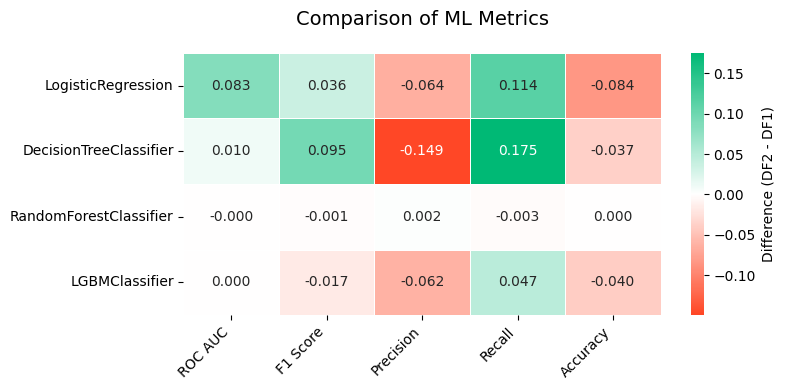

In [145]:
compare_metrics_heatmap(initial_metrics, balanced_metrics)

#### 2.10.2 Используя SMOTE

In [146]:
preprocessor_smote = clone(preprocessor)

preprocessor_smote.steps.append(
    ('smote', SMOTE(random_state=SEED))
)

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 29724, number of negative: 29724
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.009345 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2964
[LightGBM] [Info] Number of data points in the train set: 59448, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 29724, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004452 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2966
[LightGBM] [Info] Number of data points in the train set: 59448, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 29724, number of neg

<Figure size 1500x600 with 0 Axes>

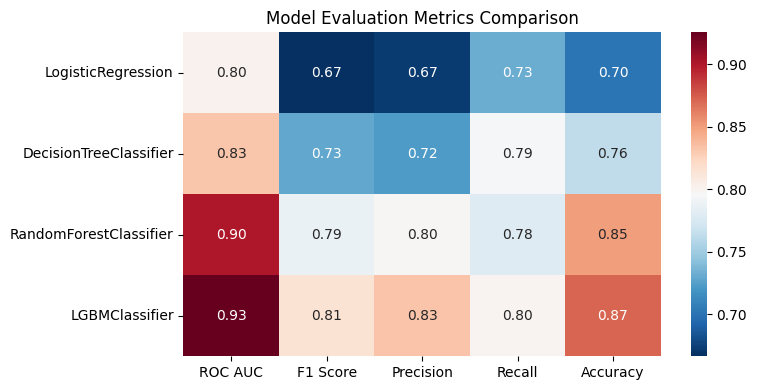

In [147]:
smote_metrics = train_evaluate_models_cv(
    models=models,
    X=X,
    y=y,
    preprocessor=preprocessor_smote,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                          ROC AUC  F1 Score  Precision    Recall  Accuracy
 LogisticRegression      0.079808  0.030264  -0.066385  0.113346 -0.093424
 DecisionTreeClassifier -0.010314  0.076680  -0.160820  0.165851 -0.057758
 RandomForestClassifier -0.005956 -0.003480  -0.018014  0.005444 -0.007555
 LGBMClassifier         -0.002468 -0.000444  -0.006914  0.003245 -0.002068)

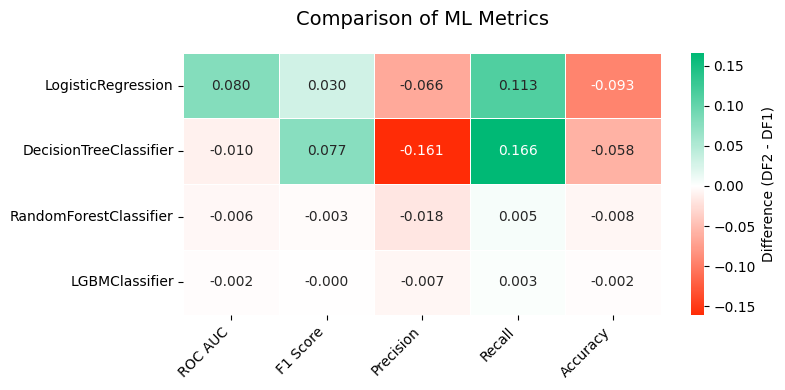

In [148]:
compare_metrics_heatmap(initial_metrics, smote_metrics)

Нет заметных улучшений

### 2.11 Итоговый результат

К сожалению, из всех преобразований ничего не дало существенных улучшений((